# Organograma

## Importação e Tratamento

In [1]:
import pandas as pd 
df = pd.read_csv('../radarrj_ato_limpo.csv', sep='|')
print(len(df))

90450


In [2]:
df['id'] = df['id'].astype(int)
df['dataPubli'] = pd.to_datetime(df['dataPubli'])
df = df.sort_values(by='dataPubli', ascending=True)
df = df.reset_index(drop=True)
df.tail(1)

,id,idExPaAux,createdAt,dataPubli,parte,secao,subsecao,norma,texto
90449,2745582,3603076,2026-07-01 12:14:38,2026-07-01,Parte II (Poder Legislativo),Expediente Despachado pelo Presidente,NaN,II - Ofícios,PROJETO DE LEI Nº 7929/2026 DECLARA DE UTIL...


In [3]:
df_diarios = pd.read_csv('../diarios.csv',sep = '|')

df_diarios

,id,dataPubli,secao,texto
0,1009438,NaN,SECRETARIA DE ESTADO DE ADMINISTRAÇÃO PENITENC...,ATOS DO SECRETÁRIO RESOLUÇÃO SEAP Nº 363 DE...
1,1058914,NaN,SECRETARIA DE ESTADO DE EDUCAÇÃO - SEEDUC,DECRETO Nº 42.733 DE 06 DE DEZEMBRO DE 2010 ...
2,1078413,NaN,SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGION...,DECRETO Nº 42.817 DE 26 DE JANEIRO DE 2011 ...
3,1093266,NaN,SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL,DECRETO N º 42.862 DE 23 DE FEVEREIRO DE 2011 ...
4,1124082,NaN,SECRETARIA DE ESTADO DE SEGURANÇA - SESEG,DECRETO Nº 42.940 DE 29 DE ABRIL DE 2011 AL...
...,...,...,...,...
185,806494,NaN,SECRETARIA DE ESTADO DA CASA CIVIL,DECRETO Nº 41.954 DE 17 DE JULHO DE 2009 AL...
186,828894,NaN,SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL 1...,ANEXO II A QUE SE REFERE O DECRETO Nº 42.009 ...
187,830707,NaN,SECRETARIA DE ESTADO DE EDUCAÇÃO - SEEDUC,DECRETO Nº 42.013 DE 28 DE AGOSTO DE 2009 D...
188,887811,NaN,Secretaria de Estado de Fazenda,DECRETO Nº 42.184 DE 11 DE DEZEMBRO DE 2009 ...


## Normas

In [4]:
set_normas = set(df['norma'].dropna().unique())
print(set_normas)

{'IV - Editais: Concorrências', 'IV - Editais: Outros', 'V - Ata', 'V - Extravio', 'II - IPALERJ', 'DPGE - Despacho', 'II - Indicações', 'IB - Apostila', 'II - Ofícios', 'IB - Portaria', 'I - Ato', 'IB - Edital de Comunicação (Plenário)', 'II - Emendas', 'IB - Decisão', 'IB - Ato', 'IV - Editais: Extrato de Instrumento', 'IB - Termo', 'I - Ordem de Serviço', 'IB - Errata', 'I - Decreto Normativo', 'II - Ata', 'IB - Ata', 'II - Despachos da Mesa Diretora', 'I - Extrato de Instrumento Contratual', 'IB - Edital de Citação (Plenário)', 'DOCG - Decreto Normativo', 'DOCG - Quadro Geral de Precos', 'DPGE - Extrato de Termo Aditivo', 'DOCG - Dispensa de Licitacao', 'DPGE - Ato', 'I - Edital', 'V - Avisos, Editais e Termos', 'I - Aviso', 'IB - Decisão Monocrática', 'I - Veto Parcial', 'V - Certidão', 'I - Resolução', 'IV - Atos', 'I - Resolução Conjunta', 'II - Atos do Presidente', 'DOCG - Ato', 'I - Decreto Pessoal', 'I - Extrato de Termo', 'II - Edital', 'V - Concessão de Licença', 'IB - Avis

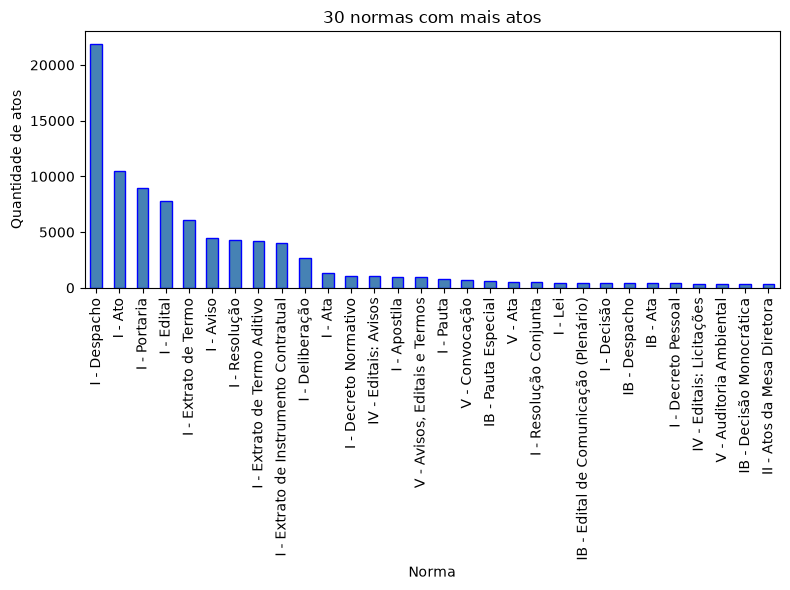

In [5]:
import matplotlib.pyplot as plt

contagem_normas = df['norma'].value_counts(dropna=True)
contagem_normas_top = contagem_normas.head(30)

ax = contagem_normas_top.plot(
    kind='bar',
    figsize=(8, 6),
    color='steelblue',
    edgecolor='blue',
    linewidth=1
)
ax.set_title('30 normas com mais atos')
ax.set_xlabel('Norma')
ax.set_ylabel('Quantidade de atos')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()

## Visualização Secretarias

In [55]:
# Lista de secretarias e órgãos que aparecem em df_diarios['secao'].unique(),
# sem repetição, com o nome escrito corretamente (sem sigla, com acento).
SECRETARIAS = [
    "Gabinete de Segurança Institucional",
    "Poder Executivo Estadual",
    "Secretaria de Estado da Casa Civil",
    "Secretaria de Estado da Casa Civil e Governança",
    "Secretaria de Estado das Cidades",
    "Secretaria de Estado de Ação Comunitária e Juventude",
    "Secretaria de Estado de Administração Penitenciária",
    "Secretaria de Estado de Agricultura, Pecuária e Abastecimento ",
    "Secretaria de Estado de Agricultura, Pecuária, Pesca e Abastecimento",
    "Secretaria de Estado de Assistência à Vítima",
    "Secretaria de Estado de Ciência, Tecnologia e Inovação",
    "Secretaria de Estado de Cultura e Economia Criativa",
    "Secretaria de Estado de Defesa Civil e do Corpo de Bombeiros Militar",
    "Secretaria de Estado de Defesa do Consumidor",
    "Secretaria de Estado de Desenvolvimento Econômico",
    "Secretaria de Estado de Desenvolvimento Regional do Interior, Pesca e Agricultura Familiar",
    "Secretaria de Estado de Desenvolvimento Regional, Abastecimento e Pesca",
    "Secretaria de Estado de Desenvolvimento Social e Direitos Humanos",
    "Secretaria de Estado de Educação",
    "Secretaria de Estado de Energia e Economia do Mar",
    "Secretaria de Estado de Envelhecimento Saudável",
    "Secretaria de Estado de Esporte, Lazer e Juventude",
    "Secretaria de Estado de Fazenda",
    "Secretaria de Estado de Fazenda e Planejamento",
    "Secretaria de Estado de Governo",
    "Secretaria de Estado de Governo e Relações Institucionais",
    "Secretaria de Estado de Governo, Comunicação e Relações Institucionais",
    "Secretaria de Estado de Habitação",
    "Secretaria de Estado de Habitação de Interesse Social",
    "Secretaria de Estado de Infraestrutura e Cidades",
    "Secretaria de Estado de Infraestrutura e Obras",
    "Secretaria de Estado de Infraestrutura e Obras Públicas",
    "Secretaria de Estado de Planejamento e Gestão",
    "Secretaria de Estado de Polícia Civil",
    "Secretaria de Estado de Polícia Militar",
    "Secretaria de Estado de Proteção e Defesa do Consumidor",
    "Secretaria de Estado de Saúde",
    "Secretaria de Estado de Saúde e Defesa Civil",
    "Secretaria de Estado de Segurança",
    "Secretaria de Estado de Segurança Pública",
    "Secretaria de Estado de Trabalho e Renda",
    "Secretaria de Estado de Transformação Digital",
    "Secretaria de Estado de Transporte e Mobilidade Urbana",
    "Secretaria de Estado de Turismo",
    "Secretaria de Estado do Ambiente",
    "Secretaria de Estado do Ambiente e Sustentabilidade",
    "Secretaria de Estado Intergeracional de Juventude e Envelhecimento Saudável",
    "Secretaria Extraordinária de Acompanhamento das Ações Governamentais Integradas da Covid-19",
    "Secretaria Extraordinária de Representação do Governo em Brasília",
]

print(f"{len(SECRETARIAS)} secretarias/órgãos na lista")

49 secretarias/órgãos na lista


In [56]:
import re
import unicodedata
from difflib import SequenceMatcher

import pandas as pd

LIMIAR = 0.87  # similaridade mínima para considerar que é a mesma secretaria

# sigla no final: " - SEEDUC", " – GSI/RJ", " -SEIJES", " (SETRANS)"
_SIGLA_FINAL = re.compile(
    r"(?:\s+[-–—]\s*[A-Z][A-Z0-9/.\s-]*|\s*\(\s*[A-Z][A-Z0-9/.\s-]*\))\s*$"
)


def chave(nome):
    """Forma normalizada para comparar: sem acento, maiúsculas, sem sigla no
    final e sem espaços/pontuação (resolve 'Educação', 'DESENVOL VIMENTO')."""
    nome = unicodedata.normalize("NFKD", str(nome))
    nome = "".join(c for c in nome if not unicodedata.combining(c)).upper()
    nome = _SIGLA_FINAL.sub("", re.sub(r"\s+", " ", nome).strip())
    return re.sub(r"[^A-Z0-9]", "", nome)


def similaridade(a, b):
    return SequenceMatcher(None, a, b, autojunk=False).ratio()


CHAVES = {chave(s): s for s in SECRETARIAS}
assert len(CHAVES) == len(SECRETARIAS), "há nomes repetidos em SECRETARIAS"


def corresponder(parte):
    """Acha a secretaria da lista para um nome. Devolve (secretaria, nota, tipo)."""
    k = chave(parte)

    # 1) nome inteiro: difere só por sigla, caixa, acento, espaço ou erro de digitação
    nota, secretaria = max((similaridade(k, kc), s) for kc, s in CHAVES.items())
    if nota >= LIMIAR:
        return secretaria, nota, "exata" if nota == 1 else "aproximada"

    # 2) texto extra depois do nome ("... DO RIO DE JANEIRO", "E DÁ OUTRAS
    #    PROVIDÊNCIAS", "1 - ÓRGÃOS..."): compara só o começo do valor. Em empate,
    #    fica o nome mais longo ('Saúde e Defesa Civil' antes de 'Saúde').
    nota, _, secretaria = max(
        (
            (similaridade(k[: len(kc)], kc), len(kc), s)
            for kc, s in CHAVES.items()
            if len(k) > len(kc)
        ),
        default=(0.0, 0, None),   # nome mais curto que todos os da lista
    )
    if nota >= LIMIAR:
        return secretaria, nota, "texto extra no final"

    return None, nota, "sem correspondência"


# guarda o valor original uma vez só, para a célula poder ser rodada de novo
if "secao_original" not in df_diarios:
    df_diarios["secao_original"] = df_diarios["secao"]

# avalia cada valor único (um campo pode ter mais de uma secretaria, separadas por ';')
linhas = []
for valor in df_diarios["secao_original"].dropna().unique():
    for parte in re.split(r"\s*;\s*", valor.strip()):
        secretaria, nota, tipo = corresponder(parte)
        linhas.append({"original": valor, "parte": parte, "secretaria": secretaria,
                       "similaridade": round(nota, 3), "tipo": tipo})
avaliacao = pd.DataFrame(linhas)


def _corrigir(valor):
    if pd.isna(valor):
        return valor
    partes = avaliacao.loc[avaliacao["original"] == valor]
    nomes = partes["secretaria"].fillna(partes["parte"])  # sem correspondência: mantém
    return "; ".join(dict.fromkeys(nomes))


df_diarios["secao"] = df_diarios["secao_original"].map(_corrigir)

print(f"Valores únicos antes: {df_diarios['secao_original'].nunique()}")
print(f"Secretarias únicas depois: {df_diarios['secao'].nunique()}")
print(avaliacao["tipo"].value_counts().to_string())

sem_match = avaliacao[avaliacao["secretaria"].isna()]
if len(sem_match):
    print("\nSem correspondência na lista (adicione em SECRETARIAS se for uma secretaria nova):")
    print(sem_match[["parte", "similaridade"]].to_string(index=False))

avaliacao[avaliacao["tipo"] != "exata"].sort_values("similaridade")

Valores únicos antes: 93
Secretarias únicas depois: 51
tipo
exata                   72
texto extra no final    22
aproximada               3


,original,parte,secretaria,similaridade,tipo
21,SECRETARIA DE ESTADO DE TRANSPORTES (SETRANS),SECRETARIA DE ESTADO DE TRANSPORTES (SETRANS),Secretaria de Estado de Turismo,0.889,texto extra no final
32,SECRETARIA DE ESTADO DE TRANSPORTES - SETRANS,SECRETARIA DE ESTADO DE TRANSPORTES - SETRANS,Secretaria de Estado de Turismo,0.889,texto extra no final
46,SECRETARIA DE ESTADO ENVELHECIMENTO SAUDÁVEL -...,SECRETARIA DE ESTADO ENVELHECIMENTO SAUDÁVEL -...,Secretaria de Estado de Envelhecimento Saudável,0.976,aproximada
64,SECRETARIA DE ESTADO DE DESENVOLIVIMENTO ECONÔ...,SECRETARIA DE ESTADO DE DESENVOLIVIMENTO ECONÔ...,Secretaria de Estado de Desenvolvimento Econômico,0.977,texto extra no final
95,SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL 1...,SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL 1...,Secretaria de Estado de Saúde e Defesa Civil,0.987,aproximada
84,SECRETARIA DE ESTADO DO AMBIENTE E SUSTETABILI...,SECRETARIA DE ESTADO DO AMBIENTE E SUSTETABILI...,Secretaria de Estado do Ambiente e Sustentabil...,0.989,aproximada
14,SECRETARIA DE ESTADO DE PROTEÇÃO E DEFESA DO C...,SECRETARIA DE ESTADO DE PROTEÇÃO E DEFESA DO C...,Secretaria de Estado de Proteção e Defesa do C...,1.000,texto extra no final
22,SECRETARIA DE ESTADO DE DESENVOLVIMENTO ECONÔM...,SECRETARIA DE ESTADO DE DESENVOLVIMENTO ECONÔM...,Secretaria de Estado de Desenvolvimento Econômico,1.000,texto extra no final
31,SECRETARIA DE ESTADO DE DESENVOLVIMENTO ECONÔM...,SECRETARIA DE ESTADO DE DESENVOLVIMENTO ECONÔM...,Secretaria de Estado de Desenvolvimento Econômico,1.000,texto extra no final
29,GABINETE DE SEGURANÇA INSTITUCIONAL DO GOVERNO...,GABINETE DE SEGURANÇA INSTITUCIONAL DO GOVERNO...,Gabinete de Segurança Institucional,1.000,texto extra no final


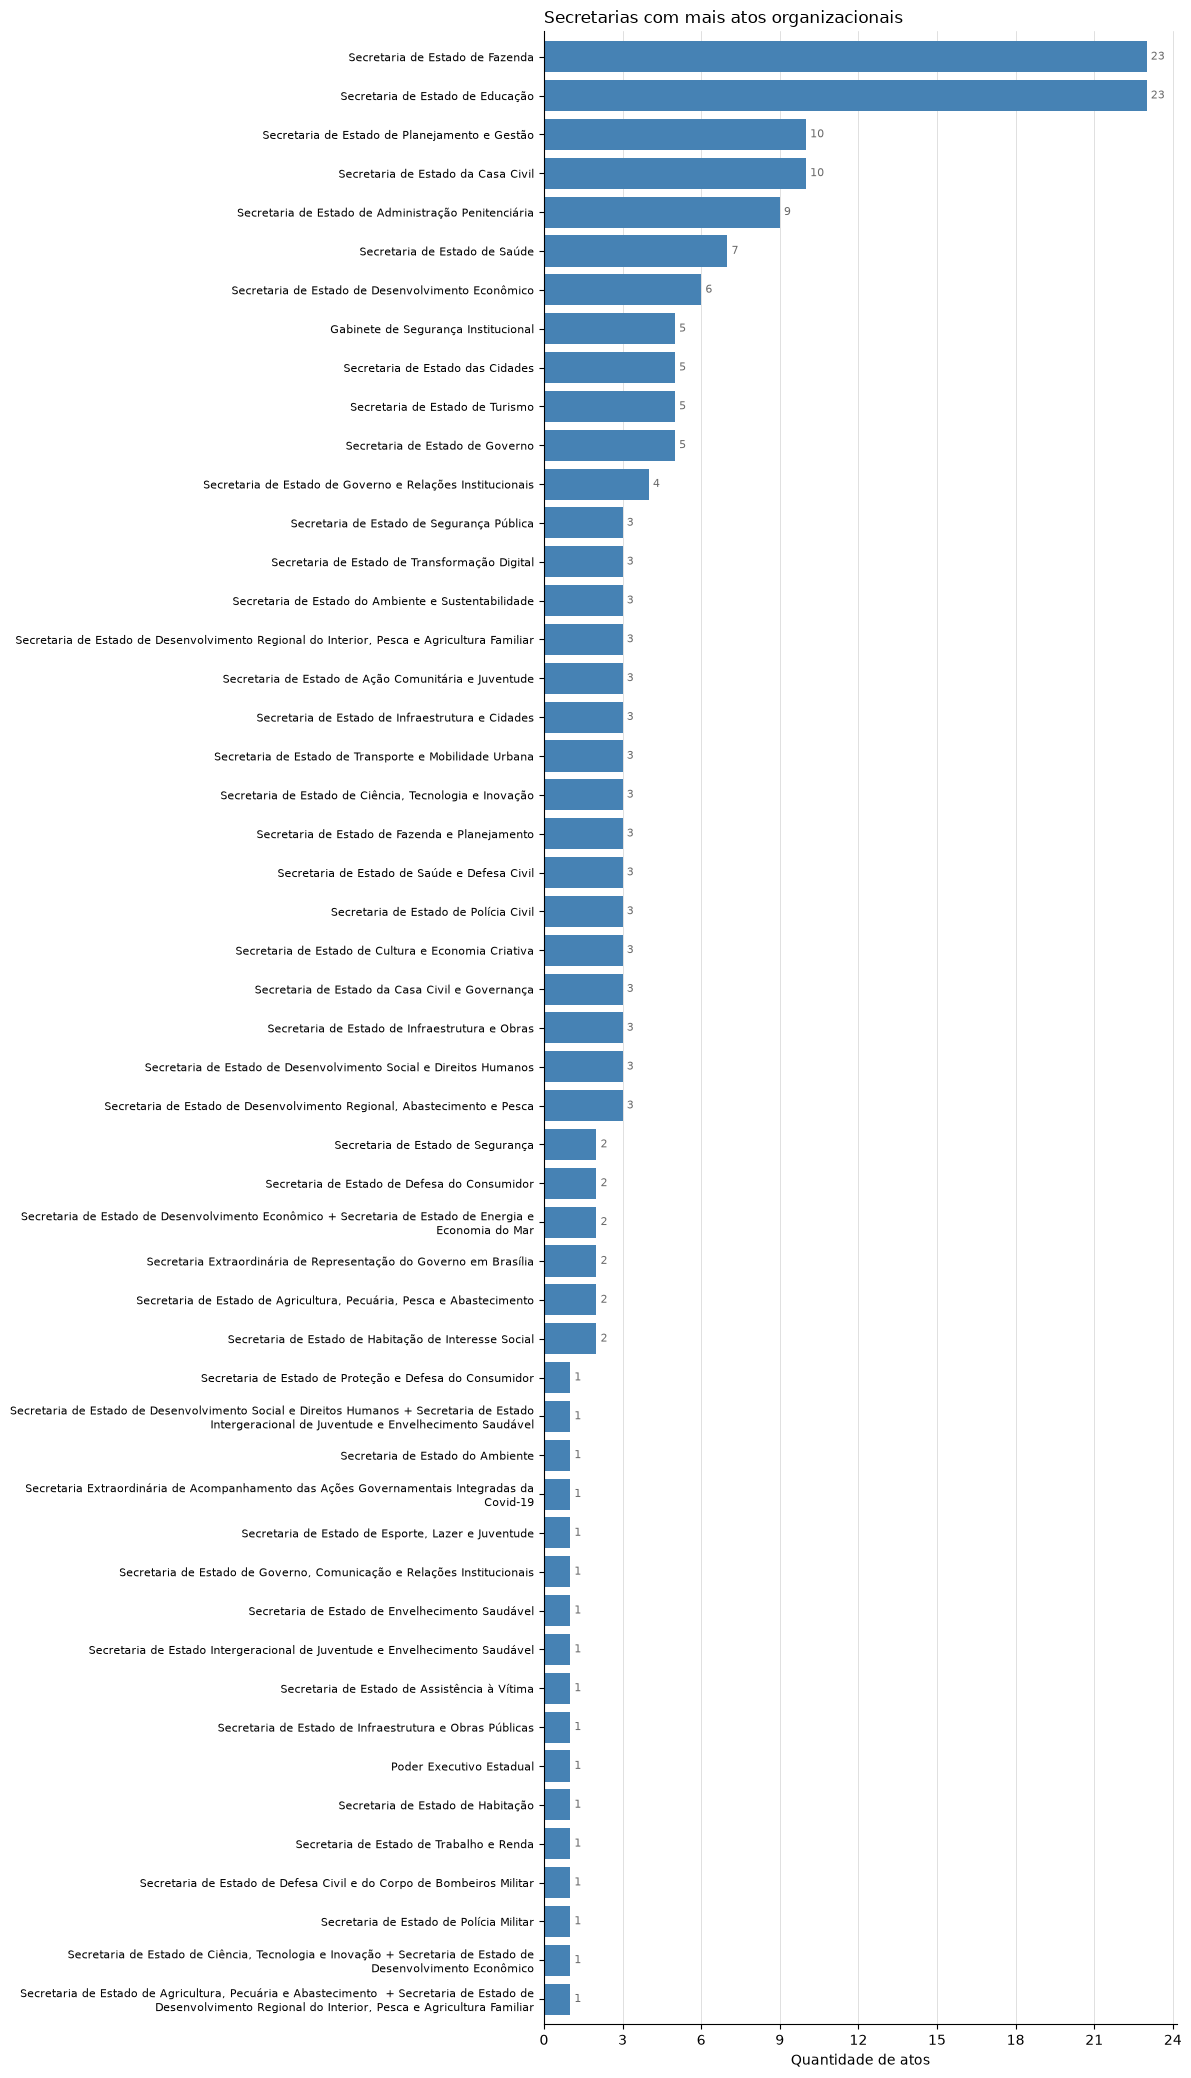

In [57]:
import textwrap

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

contagem_secretarias = df_diarios['secao'].value_counts(dropna=True).sort_values()
# nomes longos em até 2 linhas, para não espremer a área do gráfico
rotulos = [
    textwrap.fill(nome.replace('; ', ' + '), 90, max_lines=2, placeholder=' …')
    for nome in contagem_secretarias.index
]

fig, ax = plt.subplots(figsize=(12, 0.38 * len(rotulos) + 1.5))
barras = ax.barh(rotulos, contagem_secretarias.values, color='steelblue')
ax.bar_label(barras, padding=3, fontsize=8, color='dimgray')
ax.set_title('Secretarias com mais atos organizacionais', loc='left')
ax.set_xlabel('Quantidade de atos')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.tick_params(axis='y', labelsize=8)
ax.margins(y=0.005)
ax.grid(axis='x', color='lightgray', linewidth=0.5)
ax.set_axisbelow(True)
for lado in ('top', 'right'):
    ax.spines[lado].set_visible(False)
plt.tight_layout()

## Busca por atos com Organização da Secretaria

### Busca

In [6]:
import re
import unicodedata


def remover_acentos(texto):
    texto_normalizado = unicodedata.normalize("NFKD", texto)
    return "".join(
        caractere
        for caractere in texto_normalizado
        if not unicodedata.combining(caractere)
    )


# Exige pontuação depois do "1": casa "1.", "1-", "1 -", "1)", "1 )".
# NÃO casa "1 GABINETE" (sem pontuação).
padrao_gabsec = r"(?<!\d)1\s*[\.\)\-–]\s*GABINETE\s+DO\s+SECRETARIO\b"
padrao_regimento = r"\bREGIMENTO\s+INTERNO\s+DA\s+SECRETARIA\b"

texto_normalizado = df["texto"].fillna("").map(remover_acentos)

df["gabsec"] = texto_normalizado.str.contains(
    padrao_gabsec,
    case=False,
    regex=True,
    na=False,
)
df["regimento"] = texto_normalizado.str.contains(
    padrao_regimento,
    case=False,
    regex=True,
    na=False,
)

contagem_gabsec = df.loc[df["gabsec"], "norma"].value_counts(dropna=True)
contagem_regimento = df.loc[df["regimento"], "norma"].value_counts(dropna=True)

print(f"Atos encontrados: {df['gabsec'].sum()}")
print(f"Atos com regimento: {df['regimento'].sum()}")

Atos encontrados: 16
Atos com regimento: 30


In [8]:

def remover_acentos(texto):
    texto_normalizado = unicodedata.normalize("NFKD", texto)
    return "".join(
        caractere
        for caractere in texto_normalizado
        if not unicodedata.combining(caractere)
    )


padrao_estorg = (
    r"\bALTERA\s*,\s*SEM\s+AUMENTO\s+DE\s+DESPESA\s*,\s*A\s+ESTRUTURA\s+ORGANIZACIONAL\b"
)

texto_normalizado = df["texto"].fillna("").map(remover_acentos)

df["estorg"] = texto_normalizado.str.contains(
    padrao_estorg,
    case=True,
    regex=True,
    na=False,
)

contagem_gabsec = df.loc[df["estorg"], "norma"].value_counts(dropna=True)


print(f"Atos encontrados: {df['estorg'].sum()}")
print(f"Atos com regimento: {df['regimento'].sum()}")

Atos encontrados: 40
Atos com regimento: 30


In [10]:
df.loc[(df['gabsec'] == 1) & (df['estorg'] == 1)]


,id,idExPaAux,createdAt,dataPubli,parte,secao,subsecao,norma,texto,gabsec,regimento,estorg
42500,2665113,3509417,2025-11-08 22:29:45,2025-07-25,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,DECRETO Nº 49.765 DE 24 DE JULHO DE 2025 AL...,True,False,True
45617,2668616,3513558,2025-11-08 22:25:14,2025-08-08,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,DECRETO Nº 49.791 DE 07 DE AGOSTO DE 2025 A...,True,True,True
49833,2672992,3518612,2025-11-08 22:18:19,2025-08-25,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,*DECRETO Nº 49.791 DE 07 DE AGOSTO DE 2025 ...,True,True,True
68666,2694290,3543002,2025-11-14 08:05:14,2025-11-14,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,DECRETO Nº 49.979 DE 13 DE NOVEMBRO DE 2025 ...,True,False,True
69534,2695788,3544853,2025-11-24 08:05:24,2025-11-24,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,DECRETO Nº 50.003 DE 19 DE NOVEMBRO DE 2025 ...,True,False,True
86995,2735086,3590734,2026-05-15 11:34:42,2026-05-15,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,*DECRETO Nº 50.279 DE 30 DE ABRIL DE 2026 A...,True,False,True
87309,2735465,3591098,2026-05-18 17:03:32,2026-05-18,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,*DECRETO Nº 50.280 DE 30 ABRIL DE 2026 ALTE...,True,False,True
88293,2740714,3597309,2026-06-10 11:03:45,2026-06-10,Parte I (Poder Executivo),Atos do Poder Executivo,NaN,I - Decreto Normativo,DECRETO Nº 50.325 DE 09 DE JUNHO DE 2026 AL...,True,False,True


### Função extração organização

In [62]:
import json
import re
import unicodedata


# ============================================================ util de texto
def normalizar_texto(texto):
    if texto is None:
        return ""
    texto = str(texto)
    texto = texto.replace("&nbsp;", " ").replace("\xa0", " ")
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    return texto


def indice_para_tupla(indice):
    indice = str(indice).strip()
    if not re.fullmatch(r"\d+(?:\.\d+)*", indice):
        return None
    return tuple(int(p) for p in indice.split("."))


_ROMANO_VAL = {
    "i": 1, "ii": 2, "iii": 3, "iv": 4, "v": 5, "vi": 6, "vii": 7, "viii": 8,
    "ix": 9, "x": 10, "xi": 11, "xii": 12, "xiii": 13, "xiv": 14, "xv": 15,
    "xvi": 16, "xvii": 17, "xviii": 18, "xix": 19, "xx": 20,
}


def _romano_para_int(r):
    return _ROMANO_VAL.get(re.sub(r"\s+", "", str(r).lower()))


_MINUSC = {"de", "da", "do", "das", "dos", "e", "a", "o", "as", "os", "em", "para", "com"}


def _titlecase_pt(txt):
    """Title-case mantendo conectivos (de, da, do, e...) em minúsculo."""
    if not txt.isupper():
        return txt
    return " ".join(
        p if (p.lower() in _MINUSC and i) else p.capitalize()
        for i, p in enumerate(txt.split())
    )


def extrair_sigla_e_nome(nome):
    """Separa '... - SIGLA' / '... (SIGLA)' do nome. Só considera sigla se for
    curta e em CAIXA ALTA (evita 'E-Social', '(Fundacao CEPERJ)')."""
    nome = re.sub(r"\s+", " ", str(nome)).strip()
    nome = re.sub(r"\s*\(\.*\)\s*$", "", nome).strip()          # '(...)' placeholder
    if not nome:
        return "", None
    # nota no fim ("... - CELF (Em liquidacao)"): sai para achar a sigla e volta no nome
    mnota = re.search(r"\s*\((em\s+liquida[cç][aã]o|extint[ao])\)\s*$", nome, flags=re.I)
    if mnota:
        base, sigla = extrair_sigla_e_nome(nome[:mnota.start()])
        return f"{base} ({mnota.group(1)})", sigla
    m = re.search(r"^(.*?)(?:\s*\(([^()]{2,40})\)|\s*[-–]\s*([A-Z][A-Z0-9./\-]{1,18}))\s*$", nome)
    if m:
        base = (m.group(1) or "").strip(" -–:;,.")
        sigla = (m.group(2) or m.group(3) or "").strip()
        if re.fullmatch(r"[A-Z][A-Z0-9./\-]{1,18}", sigla) and base:
            return base, sigla
    return nome.strip(" -–:;,.()"), None


# ================================================ nome da secretaria (fallback)
def _limpar_nome_secretaria(nome):
    nome = re.sub(r"\s+", " ", str(nome)).strip()
    # corta em cabeçalho de seção romana / de estrutura que tenha grudado no nome
    nome = re.split(
        r"\s+(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s+[A-ZÀ-Ý]"
        r"|\bESTRUTURA\s+(?:BASICA|ORGANIZACIONAL)"
        r"|\bORGAOS?\s+DE\s+ASSISTENCIA"
        r"|\bA\s+QUE\s+SE\s+REFERE",
        nome, maxsplit=1, flags=re.IGNORECASE,
    )[0]
    nome = re.sub(
        r"^(?:[IVXLC]+\s*[-.–]\s*)?(?:A|O|AS|OS|DA|DO|DE)\s+(?=SECRETARI|GABINETE)",
        "", nome, flags=re.IGNORECASE,
    )
    nome = re.sub(r"\s+[A-Za-z]\s*$", "", nome)      # letra solta no fim ("... DIGITAL A")
    nome = nome.strip(" -–:;,.()")
    return nome.upper()


def _secretaria_pelo_texto(texto_norm, offset_gab):
    antes = re.sub(r"\s+", " ", texto_norm[:offset_gab]).strip()
    if not antes:
        return None

    # (B) cabeçalho SECRETARIA/GABINETE ... imediatamente antes do gabinete
    mb = re.search(
        r"(SECRETARI[AO]|GABINETE)\s+"
        r"((?:DE|DO|DA|EXTRAORDINARI[AO])(?:\s+[A-Z0-9&/().,\-]+)+?)"
        r"\s*[:;.\-]*\s*$",
        antes,
    )
    if mb:
        pref = "SECRETARIA" if mb.group(1).upper().startswith("SECRETARI") else "GABINETE"
        nome = _limpar_nome_secretaria(f"{pref} {mb.group(2)}")
        if len(nome) >= 10:
            return nome

    # (A) "estrutura (organizacional|basica) d_ <nome>"
    ma = list(re.finditer(
        r"estrutura\s+(?:organizacional|basica)\s+d[aeo]\s+(.+?)\s*"
        r"(?:[,.:(]|\bna\s+forma\b|\bconforme\b|\bcompreende\b|\bcompete\b"
        r"|\bsera\b|\btera\b|\bpassa\w*|\bfica\w*\b|\be\s+d[ao]s?\b"
        r"|\s(?:I{1,3}|IV|VI{0,3}|X|V)\s*[-–]\s|$)",
        antes, flags=re.IGNORECASE,
    ))
    if ma:
        nome = _limpar_nome_secretaria(ma[-1].group(1))
        if len(nome) >= 10 and re.search(r"SECRETARI|GABINETE", nome):
            return nome

    # (C) última menção "Secretari_ de ..."
    mc = list(re.finditer(
        r"(SECRETARI[AO]\s+(?:DE|DO|DA|EXTRAORDINARI[AO])\s+[A-Za-z0-9&/().,\-\s]+?)"
        r"(?:[,.:(]|\bna\s+forma\b|\bconforme\b|\bsera\b|\btera\b|\bque\b|\btem\b"
        r"|\s(?:I{1,3}|IV|VI{0,3}|X|V)\s*[-–]\s|$)",
        antes, flags=re.IGNORECASE,
    ))
    if mc:
        nome = _limpar_nome_secretaria(mc[-1].group(1))
        if len(nome) >= 10 and "SECRETARI" in nome:
            return nome
    return None


def _resolver_secretaria(texto_norm, offset_gab, secao):
    if secao is not None:
        s = str(secao).strip()
        if re.match(r"^(secretaria|gabinete)\b", s, flags=re.IGNORECASE):
            # 'secao' já vem só com o(s) nome(s); corta um eventual "I - ORGAOS..."
            return _limpar_nome_secretaria(s)
    if offset_gab is not None:
        return _secretaria_pelo_texto(texto_norm, offset_gab)
    return None


# =================================================== deteccao do "1. Gabinete"
# AGORA exige pontuação depois do "1" (não casa "1 Gabinete do Secretario")
PADRAO_GABINETE = re.compile(
    r"(?<!\d)1\s*[.)\-–]\s*gabinete\s+d[aoe]s?\s*secretari[oa]",
    flags=re.IGNORECASE,
)

# sem "1. Gabinete do/da Secretário/a", o item 1 pode ser a própria secretaria ou a
# presidência, desde que venha seguido do resto do organograma:
#   "1 - Secretaria de Estado de Polícia Militar   1.1 - Chefia de Gabinete"
#   "1 . PRESIDÊNCIA   1.1. Chefia de Gabinete da Presidência" / "1. Presidência   2. Diretoria"
_RX_RAIZ_SECRETARIA = re.compile(
    r"(?<![\d.])1\s*[.)\-–]\s*(secretaria\s+(?:de\s+estado|extraordinaria)\b[^\n]{3,150}?)"
    r"\s*[:;.\-–]?\s*(?=1\s*\.\s*1(?:\s*\.\s*\d+)*\s*[.)\-–]?\s*[A-Za-z])",
    flags=re.IGNORECASE,
)
_RX_RAIZ_PRESIDENCIA = re.compile(
    r"(?<![\d.])1\s*[.)\-–]\s*presidencia\s*[:;.\-–]?\s*"
    r"(?=(?:1\s*\.\s*1|2)(?!\d)(?:\s*\.\s*\d+)*\s*[.)\-–]?\s*[A-Za-z])",
    flags=re.IGNORECASE,
)
# nome que o item 1 (raiz da árvore) precisa ter, conforme o tipo de início achado
_RX_NOME_RAIZ = {
    "gabinete": re.compile(r"gabinete\s+d[aoe]s?\s*secretari[oa]|gabinete\s+secretaria", re.I),
    "secretaria": re.compile(r"^secretaria\b", re.I),
    "presidencia": re.compile(r"^presidencia\b", re.I),
}


def procurar_inicio_organograma(texto):
    """(offset, tipo) do item 1 do organograma; (None, None) se não achar.
    tipo 'secretaria' só vale se o nome estiver na lista SECRETARIAS
    (usa corresponder, da normalização da coluna secao)."""
    texto = normalizar_texto(texto)
    raiz_secretaria = next(
        (s for s in _RX_RAIZ_SECRETARIA.finditer(texto) if corresponder(s.group(1))[0] is not None), None
    )
    m = PADRAO_GABINETE.search(texto)
    if m:
        # "1. Secretaria de Estado de X   1.1. Gabinete do Secretário": o gabinete é o 1.1
        if raiz_secretaria and 0 <= m.start() - raiz_secretaria.end() <= 6:
            return raiz_secretaria.start(), "secretaria"
        return m.start(), "gabinete"
    if raiz_secretaria:
        return raiz_secretaria.start(), "secretaria"
    m = _RX_RAIZ_PRESIDENCIA.search(texto)
    if m:
        return m.start(), "presidencia"
    return None, None


def procurar_inicio_gabinete(texto):
    return procurar_inicio_organograma(texto)[0]


# ================================================ seções de nível 1 (listas)
_CATS = [
    ("Entes Vinculados", re.compile(
        r"(?:entes?|entidades?)\s+(?:e\s+(?:entes?\s+)?)?vinculad"
        r"|(?:entes?|entidades?)\s+supervisionad"
        r"|\bsupervisionad[oa]s?\b"
        r"|^\W*orgaos?\s+e\s+entidades?\s+vinculad"
        r"|^\W*orgaos?\s+vinculad\w*\s*:?\s*$"
        r"|^\W*orgao\s+vinculad"
        r"|^\W*empresas?\s+(?:publicas?\s+)?vinculad", re.I)),
    ("Orgaos Colegiados", re.compile(r"orgaos?\s+colegiad|^\W*colegiad", re.I)),
    ("Comissoes", re.compile(r"^\W*comiss[oõa]", re.I)),
    ("Fundos", re.compile(r"\bfundos?\b|administracao\s+de\s+fundos", re.I)),
]
_CAT_NOMES = [c for c, _ in _CATS]

# títulos de seção romana que, apesar da palavra "vinculad", SÃO parte da árvore
_RX_SECAO_ARVORE = re.compile(
    r"especific|singular|subordinad|assistencia\s+direta|ao\s+secretario"
    r"|a\s+chefia|ao\s+gabinete|de\s+planejamento|de\s+coordenacao"
    r"|de\s+correicao|de\s+inteligencia|de\s+assessoramento|de\s+representacao"
    r"|de\s+atividades", re.I,
)


def _classificar_secao(titulo):
    if _RX_SECAO_ARVORE.search(titulo):
        return None
    for nome, rx in _CATS:
        if rx.search(titulo):
            return nome
    return None


# começo provável do nome de um ente/órgão numa lista corrida
_ORG_INI = (
    r"Conselh\w+|Comit[eê]\w*|Comiss[aã]o|C[aâ]mara|Junta|F[oó]rum|Sistema"
    r"|Fund\w+|Companhia|Institut\w+|Departament\w+|Empresa|Ag[eê]ncia|Autarquia"
    r"|Superintend\w+|Centro|Programa|Coordenad\w+|Secretaria|Nucleo|Servico"
    r"|Escritorio|Diretoria|Assessoria|Loteria|Imprensa|Radio|Universidade"
)
_RX_ORG_INI = re.compile(r"(?<![A-Za-zÀ-ÿ])(?:%s)\b" % _ORG_INI, re.I)
_RX_ORG_SPLIT = re.compile(r"(?<=[a-zç0-9)\]])\s+(?=(?:%s)\b)" % _ORG_INI, re.I)
# não separar "Fundacao Instituto ...", "Conselho Gestor do Fundo ..." etc:
# palavras que formam nome composto com o próximo termo-início
_RX_NAO_SEPARAR = re.compile(
    r"\b(?:Fundacao|Fundo|Instituto|Conselho|Companhia|Departamento|Ag[eê]ncia"
    r"|Centro|C[aâ]mara|Superintend\w+|Coordenad\w+|Comiss[aã]o|Comit[eê]"
    r"|Sistema|Servico|Nucleo|Escritorio|Diretoria|Assessoria|Junta|Secretaria"
    r"|Universidade|Autarquia|de|d[oa]s?|e|para|com)\s*$", re.I,
)
_RX_CORTA_LISTA = re.compile(
    r"\bANEXO\s+[IVX0-9]|\bId:\s*\d|\bCAP[IÍ]TULO\b|\bT[IÍ]TULO\b|\bSUBSE[CÇ][AÃ]O"
    r"|COMPET[EÊ]NCIAS?\s+E?\s*ATRIBUI|\bArt\.?\s*\d"
    r"|\b(?:Rio de Janeiro|Brasilia),?\s+\d?\d\s+de\s+\w+\s+de\s+\d{4}"
    r"|(?:^|\s{2,})(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s+[A-ZÀ-Ý]{2,}\b",
    re.I,
)


def _parse_lista_entes(corpo):
    corpo = _RX_CORTA_LISTA.split(corpo, maxsplit=1)[0]
    corpo = re.sub(r"^\s*(?:e\s*/?\s*ou\s+|/\s*)?supervisionad[oa]s?\b\s*:?", "", corpo, flags=re.I)
    corpo = re.sub(r"(?<![A-Za-zÀ-ÿ])[a-z]\)\s*", "  ", corpo)   # marcadores a) b)
    corpo = corpo.replace("§", "  ").replace("·", "  ").replace("•", "  ")
    corpo = re.sub(r"[ \t]{2,}|\n", "\n", corpo)                  # blocos -> linhas
    itens, vistos = [], set()

    for pedaco in corpo.split("\n"):
        pedaco = pedaco.strip(" ;.,-–•")
        if len(pedaco) < 4:
            continue
        # separa "Conselho X   Conselho Y" (um ente ao lado do outro), sem
        # quebrar nomes compostos ("Fundacao Instituto ...")
        marcado = []
        pos = 0
        for m in _RX_ORG_SPLIT.finditer(pedaco):
            if not _RX_NAO_SEPARAR.search(pedaco[max(0, m.start() - 25):m.start()]):
                marcado.append(pedaco[pos:m.start()])
                pos = m.end()
        marcado.append(pedaco[pos:])
        subs = []
        for chunk in marcado:
            subs += re.split(
                r"(?<=[a-z])(?=[A-Z][a-zç])"        # "...FIAFundacao"
                r"|(?<=[A-Z]{2})(?=[A-Z][a-zç])"    # "...INEAFundo"
                r"|\s*;\s*",
                chunk,
            )
        for s in subs:
            s = re.sub(r"^\s*\d+(?:\.\d+)*\s*[.)\-–]?\s*", "", s)   # tira "1.1 "
            s = re.sub(r"[;,]?\s+e$", "", s.strip(" ;.,-–"))        # tira "; e"
            if len(s) < 4 or not re.search(r"[A-Za-zÀ-ÿ]{3}", s):
                continue
            nome, sigla = extrair_sigla_e_nome(s)
            nome = re.sub(r"\s+", " ", nome).strip(" ;.,-–")
            if len(nome) < 4:
                continue
            chave = (nome.lower(), sigla)
            if chave not in vistos:
                vistos.add(chave)
                itens.append({"nome": nome, "sigla": sigla})
    return itens


# ================================================= corte do nome de entidade
_RX_CORTA_NOME = re.compile(
    r"\s+(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s+[A-ZÀ-Ý]"      # " II - Xxx"
    r"|(?<=\S)\s+(?:Cargo\s+em\s+Comiss[aã]o|Denomina[cç][aã]o|Quantitativo)\s+S[ií]mbolo"
    r"|(?<=\S)\s+S[ií]mbolo\s+(?:Qt\b|Quant|N[ºo°]|Refer)"
    r"|(?<=\S)\s+(?:CAP[IÍ]TULO|T[IÍ]TULO|SE[CÇ][AÃ]O|SUBSE[CÇ][AÃ]O|ANEXO"
    r"|PAR[AÁ]GRAFO|Paragrafo|Par[aá]grafo)\b"
    r"|\s+Art\.?\s*\d"
    r"|\bId:\s*\d"
    r"|\s*\.{4,}"                                                     # "........"
    r"|\s*§"
    r"|(?<=[a-zç])\s+[a-z]\)\s"                                       # " a) assessorar..."
    r"|(?<=\S)\s+Compete\b"
    r"|(?<=\S)\s+P\s*ar[aá]grafo\b"
    r"|(?<=\S)\s+(?:ENTIDADES?|ENTES?)\s+(?:E\s+ENTES?\s+)?VINCULAD"
    r"|(?<=\S)\s+[OÓ]RG[AÃ]OS?\s+(?:E\s+ENTIDADES?\s+)?(?:VINCULAD|COLEGIAD)"
    r"|(?<=\S)\s+(?:D[AO]S?\s+)?COMPET[EÊ]NCIAS?\s+E?\s*ATRIBUI"
    r"|(?<=\S)\s+(?:Rio de Janeiro|Bras[ií]lia),?\s+\d?\d\s+de\s+\w+\s+de\s+\d{4}"
    r"|(?<=\S)\s+(?:CLAUDIO\s+CASTRO|SERGIO\s+CABRAL|LUIZ\s+FERNANDO|WILSON\s+WITZEL"
    r"|RICARDO\s+COUTO|Governador(?:\s+em\s+Exerc[ií]cio)?)\b",
    re.IGNORECASE,
)

# marca o fim da parte "estrutura" (começo do regimento / assinaturas / anexos)
_RX_FIM_ESTRUTURA = re.compile(
    r"\bCAP[IÍ]TULO\s+[IVX0-9]"
    r"|\bT[IÍ]TULO\s+[IVX0-9]"
    r"|\bANEXO\s+[IVX0-9]"
    r"|\bId:\s*\d"
    r"|\*?\s*Republicad\w*"
    r"|\bArt\.?\s*\d+\s*[.ºo°]?\s*[-–]"
    r"|\b(?:Rio de Janeiro|Bras[ií]lia),?\s+\d?\d\s+de\s+\w+\s+de\s+\d{4}"
    r"|\bDECRETA\s*:|\bResolve\s*:"
    r"|\b(?:D[AO]S?\s+)?COMPET[EÊ]NCIAS?\s+E?\s*ATRIBUI"
    r"|(?<![A-Za-z])(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s*(?:D[AO]S?\s+)?COMPET[EÊ]NCIA"
    r"|\bDISPOSI[CÇ][OÕ]ES\s+(?:FINAIS|GERAIS|TRANSITORIAS|PRELIMINARES)"
    r"|\bREGIMENTO\s+INTERNO\s+D"
    r"|\bAos?\s+[oó]rg[aã]os\s+integrantes\s+da\s+estrutura",
    re.I,
)


def _pre_normalizar_bloco(bloco):
    """Insere separador antes de índices/cabeçalhos romanos que vieram grudados
    no texto (artefato de extração do HTML): 'Gabinete1.2.' / 'GABSEC1.1.' /
    'InternaII -'. Preserva os '   ' (separadores de bloco) do diário."""
    # índice com espaço dentro (tags <b> do HTML): "1. 2 ." / "3 . 1 . 1 ." / "4 .Comissoes"
    # (não junta ordinal: "1.7.7.2. 1a Comissao")
    bloco = re.sub(
        r"(?<![\d.])\d{1,3}(?: ?\. ?\d{1,3}(?![\dA-Za-z]))+(?: ?\.)?|(?<![\d.])\d{1,3} \.(?=\S)",
        lambda m: m.group(0).replace(" ", ""), bloco,
    )
    bloco = re.sub(
        r"(?<=[A-Za-zçãõáéíóúâÀ-ÿ])(\d{1,3}(?:\.\d{1,3})+\.?)(?=[ .]?[A-ZÀ-Ý])",
        r"   \1 ", bloco,
    )
    # índice de 1 nível grudado numa sigla: "... - ASSGOV2. Subsecretaria"
    bloco = re.sub(
        r"(?<=[a-zçãõA-Z])([1-9]\.)(?=\s*[A-ZÀ-Ý][a-zà-ÿ])",
        r"   \1 ", bloco,
    )
    bloco = re.sub(
        r"(?<=[a-zçãõáéíóúâ])(I{2,3}|IV|VI{0,3}|IX|XI{0,3})(\s*[-–]\s+)(?=[A-ZÀ-Ý])",
        r"   \1\2", bloco,
    )
    return bloco


# cabeçalho de seção romana dentro do bloco (depois do gabinete)
_RX_ROMANO_HEADER = re.compile(
    r"(?<![A-Za-zÀ-ÿ0-9])"
    r"(I{1,3}|I\s*V|VI{0,3}|I\s*X|X\s*I{0,3}|X|V)"
    r"\s*[-–]\s*"
    r"([A-ZÀ-Ý][^\n]{2,90}?)"
    r"(?=\s{2,}|\s+\d+\s*[.)\-–]|\s*:|\s*$)",
)


def _dividir_secoes(bloco):
    """Divide o bloco em (romano_int, titulo, corpo). O trecho antes do 1º
    cabeçalho romano é a seção 1 (o Gabinete)."""
    headers = list(_RX_ROMANO_HEADER.finditer(bloco))
    secoes = []
    if not headers or headers[0].start() > 0:
        fim = headers[0].start() if headers else len(bloco)
        secoes.append((1, "", bloco[:fim]))
    for i, h in enumerate(headers):
        ini = h.end()
        fim = headers[i + 1].start() if i + 1 < len(headers) else len(bloco)
        secoes.append((_romano_para_int(h.group(1)), h.group(2).strip(), bloco[ini:fim]))
    return secoes


_RX_ENTIDADE = re.compile(
    r"(?<!\d)(\d+(?:\.\d+)*)\s*[.)\-–]?\s*(.*?)"
    r"(?=(?:\s+(?<!\d)\d+(?:\.\d+)*(?!\d)\s*[.)\-–\s])|$)",
    flags=re.S,
)


def _e_sucessor(prev, cur):
    """cur é um índice plausível depois de prev? (desce no mesmo ramo, ou é o
    próximo irmão/tio com incremento de 1 ou 2). Derruba números soltos do
    texto (quantidades de tabela, anos, nº de lei)."""
    if prev is None:
        return True
    if len(cur) >= len(prev) and cur[:len(prev)] == prev:
        return True
    for j in range(1, min(len(cur), len(prev)) + 1):
        if cur[:j - 1] == prev[:j - 1] and 1 <= cur[j - 1] - prev[j - 1] <= 2:
            return True
    return False


# rótulo de agrupamento que virou "nome" de um nó numerado
_RX_ROTULO_LIGA = re.compile(          # mantém como nó de ligação (nome curto)
    r"^[-–\s]*[OÓ]RG[AÃ]OS?\s+(?:E\s+ENTIDADES?\s+)?"
    r"(?:ESPECIFICO\w*(?:\s+SINGULAR\w*)?|DE\s+ATIVIDADES\s+\w+|DE\s+APOIO)", re.I,
)
_RX_ROTULO_DESCARTA = re.compile(      # descarta o nó inteiro
    r"^[-–\s]*(?:PROGRAMAS?\b|ATIVIDADES\s+AUXILIARES|COMISS[OÕ]ES\b"
    r"|[OÓ]RG[AÃ]OS?\s+(?:COLEGIAD|VINCULAD))", re.I,
)


def _limpar_nome_entidade(nome):
    nome = _RX_CORTA_NOME.split(nome, maxsplit=1)[0]
    # nome que atravessa um separador de bloco do diário (>=3 espaços) foi
    # "engolido": fica só com o primeiro bloco
    nome = re.split(r"\s{3,}", nome, maxsplit=1)[0]
    nome = re.sub(r"^[\s.\-–:;)]+", "", nome)
    nome = re.sub(r"[;,]?\s+e$", "", nome)                       # "...; e" / "..., e"
    nome = re.sub(r"[\s.\-–:;(]+$", "", nome)
    nome = re.sub(r"\s+", " ", nome)
    if _RX_ROTULO_DESCARTA.match(nome):
        return ""
    mliga = _RX_ROTULO_LIGA.match(nome)
    if mliga:
        return _titlecase_pt(mliga.group(0).strip(" -–"))
    return nome


_RX_TITULO_LIMPO = re.compile(
    r"\s+(?:VINCULAD\w*|SUBORDINAD\w*|SUPERVISIONAD\w*|AO\s+SECRETARIO|A\s+CHEFIA"
    r"|DO\s+SECRETARIO|E\s+IMEDIATA|DIRETA\s+E|D[EO]\s+ESTADO).*$", re.I,
)


def _titulo_secao_limpo(titulo):
    t = _RX_TITULO_LIMPO.sub("", titulo).strip(" -–:;,.")
    t = re.sub(r"\s+", " ", t)
    return _titlecase_pt(t)


def _parse_secao_arvore(corpo, romano_int, titulo, entidades, max_invalidas=6):
    """Extrai as entidades numeradas de uma seção. Se a numeração reinicia em
    '1' numa seção romana != 1, prefixa os índices com o número da seção.
    Se a seção tem filhos 'N.x' mas nenhum nó 'N', cria um a partir do título."""
    matches = list(_RX_ENTIDADE.finditer(corpo))
    # maior índice de 1º nível das seções anteriores (para saber se esta continua a numeração)
    maior_topo = max((int(k.split(".")[0]) for k in entidades), default=0)
    prefixo = None
    ultimo = None
    invalidas = 0
    vistos_sec = set()

    for m in matches:
        indice = m.group(1)
        if re.match(r"0\d", indice):          # "01", "05" -> quantidade de tabela
            continue
        tup = indice_para_tupla(indice)
        if tup is None:
            continue

        # decide o prefixo na 1ª entidade válida da seção
        if prefixo is None and romano_int and romano_int != 1:
            if tup[0] == romano_int or (tup[0] != 1 and tup[0] in (maior_topo, maior_topo + 1)):
                prefixo = 0                    # já está global (bate com o romano ou continua a anterior)
            else:
                prefixo = romano_int           # numeração local (recomeça em 1 ou salta) -> reindexar
        if prefixo:
            tup = (prefixo,) + tup[1:] if len(tup) > 1 else (prefixo,)
            indice = ".".join(str(x) for x in tup)

        nome = _limpar_nome_entidade(m.group(2) or "")
        if not nome or not re.search(r"[A-Za-zÀ-ÿ]", nome):
            invalidas += 1
            if invalidas >= max_invalidas:
                break
            continue

        if ultimo is not None and not _e_sucessor(ultimo, tup):
            invalidas += 1
            if invalidas >= max_invalidas:
                break
            continue

        nome_limpo, sigla = extrair_sigla_e_nome(nome)
        if not nome_limpo:
            invalidas += 1
            continue

        if indice not in entidades:
            entidades[indice] = {
                "indice": indice, "nome": nome_limpo, "sigla": sigla, "filhos": [],
            }
            ultimo = tup
            invalidas = 0
            vistos_sec.add(tup[0])

    # seção romana com filhos "N.x" mas sem o nó "N" -> cria a partir do título
    for topo in vistos_sec:
        chave = str(topo)
        if chave not in entidades and titulo:
            rot = _titulo_secao_limpo(titulo)
            if rot and len(rot) >= 4:
                entidades[chave] = {
                    "indice": chave, "nome": rot, "sigla": None, "filhos": [],
                }


def _montar_arvore(entidades):
    pai_de = {}
    for indice in entidades:
        partes = indice.split(".")
        pai = None
        for k in range(len(partes) - 1, 0, -1):
            cand = ".".join(partes[:k])
            if cand in entidades:
                pai = cand
                break
        pai_de[indice] = pai
    ordem = sorted(entidades, key=lambda x: indice_para_tupla(x))
    for indice in ordem:
        if pai_de[indice] is not None:
            entidades[pai_de[indice]]["filhos"].append(entidades[indice])
    return [entidades[i] for i in ordem if pai_de[i] is None], ordem, pai_de


_RX_NOME_CATEGORIA = re.compile(
    r"^(?:entes?|entidades?|orgaos?|empresas?)\s+(?:e\s+(?:entidades?\s+|entes?\s+)?)?"
    r"(?:vinculad|supervisionad)\w*"
    r"(?:\s*(?:e\s*/?\s*ou\s+|/\s*|e\s+)supervisionad\w*)?\s*[:/]?\s*"
    r"|^(?:orgaos?\s+)?colegiad\w*\s*:?\s*"
    r"|^comiss[oõ]es\b\s*:?\s*"
    r"|^(?:administracao\s+de\s+)?fundos\b\s*:?\s*", re.I,
)


def _categoria_do_nome(nome):
    m = _RX_NOME_CATEGORIA.match(nome or "")
    if not m:
        return None
    cat = _classificar_secao(nome)
    resto = (nome[m.end():]).strip(" -–:;,.") if cat else ""
    return (cat, resto) if cat else None


def _achatar(no):
    saida = [{"nome": no["nome"], "sigla": no["sigla"]}]
    for f in no["filhos"]:
        saida.extend(_achatar(f))
    return saida


def _podar_categorias(nos, listas):
    """Percorre a árvore (em qualquer nível): se um nó é 'Entes Vinculados' /
    'Orgaos Colegiados' / ... move os descendentes para a lista de nível 1
    e remove o nó da árvore."""
    mantidos = []
    for no in nos:
        achou = _categoria_do_nome(no["nome"])
        if achou:
            cat, resto = achou
            # nome do tipo "Entidades Vinculadas Fundacao Santa Cabrini"
            if resto and len(resto) >= 4:
                for it in _parse_lista_entes(resto):
                    if it not in listas[cat]:
                        listas[cat].append(it)
            for filho in no["filhos"]:
                for item in _achatar(filho):
                    if item not in listas[cat]:
                        listas[cat].append(item)
        else:
            no["filhos"] = _podar_categorias(no["filhos"], listas)
            mantidos.append(no)
    return mantidos


# linha de tabela de cargos intercalada no organograma ("Assessor   DAS-8   05"):
# a quantidade ficava colada no índice seguinte e o engolia em _RX_ENTIDADE
_CEL = r"[A-Za-z][^\s\d]*(?: [^\s]+)*"
_RX_LINHA_TABELA = re.compile(
    r"(?<=\s{3})(?:Cargo em Comissao\s{3,}Simbolo\s{3,}Qt\.?"
    r"|" + _CEL + r"\s{3,}[A-Z]{1,4}(?:-\d{1,2})?\s{3,}\d{1,3})(?=\s{3,}|\s*$)"
)


# ============================================================ função principal
def extrair_estrutura_organizacao(texto, secao=None):
    vazio_listas = {c: [] for c in _CAT_NOMES}
    texto_norm = normalizar_texto(texto)
    offset, tipo_raiz = procurar_inicio_organograma(texto)

    secretaria = _resolver_secretaria(texto_norm, offset, secao)
    if offset is None:
        return {"raiz": None, "secretaria": secretaria, "arvore": [], **vazio_listas}

    # preserva os "   " (separadores de bloco do diário); só tira \n e tabs
    bloco = _pre_normalizar_bloco(texto_norm[offset:].replace("\n", "   ").replace("\t", " ").strip())

    # remove as linhas de tabela de cargos (ver _RX_LINHA_TABELA)
    bloco = _RX_LINHA_TABELA.sub("   ", bloco)

    # separa a "estrutura" da cauda (regimento / assinaturas / anexos)
    mfim = _RX_FIM_ESTRUTURA.search(bloco)
    bloco_estrut = bloco[:mfim.start()] if mfim else bloco

    listas = {c: [] for c in _CAT_NOMES}
    entidades = {}

    for romano_int, titulo, corpo in _dividir_secoes(bloco_estrut):
        cat = _classificar_secao(titulo) if titulo else None
        if cat:
            for item in _parse_lista_entes(corpo):
                if item not in listas[cat]:
                    listas[cat].append(item)
        else:
            _parse_secao_arvore(corpo, romano_int, titulo, entidades)

    if not entidades:
        return {"raiz": None, "secretaria": secretaria, "arvore": [], **listas}

    arvore, ordem, pai_de = _montar_arvore(entidades)

    raiz = ordem[0]
    if not _RX_NOME_RAIZ[tipo_raiz].search(entidades[raiz]["nome"]):
        return {"raiz": None, "secretaria": secretaria, "arvore": [], **listas}

    # nós (em qualquer nível) que na verdade são "Entes Vinculados /
    # Colegiados / ..." -> movem os descendentes para a lista de nível 1
    arvore_final = _podar_categorias(arvore, listas)

    # item 1 = "Secretaria de Estado de X": a secretaria fica só no campo "secretaria"
    # e a árvore começa nos filhos dela (1.1, 1.2, ...)
    if tipo_raiz == "secretaria" and arvore_final and arvore_final[0]["indice"] == raiz:
        no_secretaria = arvore_final.pop(0)
        arvore_final = no_secretaria["filhos"] + arvore_final
        if secretaria is None:
            secretaria = (corresponder(no_secretaria["nome"])[0] or no_secretaria["nome"]).upper()
        if not arvore_final:
            return {"raiz": None, "secretaria": secretaria, "arvore": [], **listas}
        raiz = arvore_final[0]["indice"]

    return {"raiz": raiz, "secretaria": secretaria, "arvore": arvore_final, **listas}

### Detecção de atos de alteração

Organograma incompleto não gera JSON de estrutura:

- **alteração** (vai para `ARQUIVO_ALTERACOES`): até `MAX_ITENS_ALTERACAO` itens, ou pontuação >= `PONTUACAO_MINIMA_ALTERACAO` somando `PESOS_ALTERACAO` (omissão `(...)` entre itens, tamanho relativo ao maior organograma da secretaria, texto de alteração antes da lista, lacunas na numeração, gabinete sem filhos; "consolida" desconta);
- **falha de extração** (vai para `ARQUIVO_FALHAS`): o texto tem muitos itens numerados, mas quase nenhum virou nó (e não há omissão na lista).

In [ ]:
import datetime
import re

import pandas as pd

MAX_ITENS_ALTERACAO = 3            # organograma com até N itens = ato só de alteração
ARQUIVO_ALTERACOES = "alteracoes.json"
ARQUIVO_FALHAS = "falhas.json"     # organogramas que a extração não conseguiu ler

# acima de MAX_ITENS_ALTERACAO, soma os pesos dos sinais de ato parcial
PESOS_ALTERACAO = {
    "omissao_na_lista": 2,         # "........" / "(...)" entre itens numerados
    "tamanho_relativo": 2,         # < LIMITE_TAMANHO_RELATIVO do maior organograma da secretaria no CSV
    "texto_de_alteracao": 1,       # "seguintes alterações", "ficam alterados dispositivos", "onde se lê"...
    "lacunas_numeracao": 1,        # >= LIMITE_LACUNAS dos nós sem pai ou sem irmão anterior
    "gabinete_sem_filhos": 1,      # "1 - Gabinete" sem nenhum 1.x
    "consolida": -3,               # "consolida" / "consolidada": estrutura completa
}
PONTUACAO_MINIMA_ALTERACAO = 3
LIMITE_TAMANHO_RELATIVO = 0.25
LIMITE_LACUNAS = 0.25

# falha de extração: o texto tem muitos itens numerados, mas quase nenhum virou nó
MIN_ITENS_NUMERADOS_FALHA = 15
LIMITE_COBERTURA_FALHA = 0.3


# ============================================================ atos de alteração
def contar_itens(estrutura):
    """Nós da árvore (todos os níveis) + itens das listas de nível 1."""
    def contar(nos):
        return sum(1 + contar(no["filhos"]) for no in nos)
    return contar(estrutura["arvore"]) + sum(len(estrutura[c]) for c in _CAT_NOMES)


def eh_alteracao(estrutura, max_itens=None):
    """Achou o '1. Gabinete do Secretário', mas o organograma veio com poucos
    itens: o ato só altera parte da estrutura (não é a estrutura completa)."""
    max_itens = MAX_ITENS_ALTERACAO if max_itens is None else max_itens
    return estrutura["raiz"] is not None and contar_itens(estrutura) <= max_itens


def _bloco_da_estrutura(texto):
    """Mesmo trecho que extrair_estrutura_organizacao lê (do gabinete ao fim da estrutura)."""
    texto_norm = normalizar_texto(texto)
    offset = procurar_inicio_gabinete(texto)
    if offset is None:
        return texto_norm, None, ""
    bloco = _pre_normalizar_bloco(texto_norm[offset:].replace("\n", "   ").replace("\t", " ").strip())
    bloco = _RX_LINHA_TABELA.sub("   ", bloco)
    mfim = _RX_FIM_ESTRUTURA.search(bloco)
    return texto_norm, offset, (bloco[:mfim.start()] if mfim else bloco)


_RX_OMISSAO = re.compile(r"\.{5,}|\(\s*\.{3,}[\s.]*\)|…")
_RX_ITEM_NUMERADO = re.compile(r"(?<![\d.])\d{1,3}(?:\.\d{1,3})*\s*[.)\-–]?\s*[A-Z]")
# "1.2 - Assessoria" / "3.1. Coordenacao" / "2.4 Superintendencia"
_RX_ITEM_LISTA = re.compile(
    r"(?<![\d.A-Za-z])\d{1,2}(?:\.\d{1,2})*\s*[.)\-–]\s*[A-Z][a-z]"
    r"|(?<![\d.A-Za-z])\d{1,2}(?:\.\d{1,2})+\s+[A-Z][a-z]"
)
_RX_TEXTO_ALTERACAO = re.compile(
    r"seguintes\s+altera|ficam?\s+alterad[oa]s?\s+(?:os\s+)?dispositivos|altera(?:m|dos)?\s+dispositivos"
    r"|como\s+segue|onde\s+se\s+l[eê]|leia-se|ficam?\s+acrescid|ficam?\s+inclu[ií]d",
    re.I,
)
_RX_CONSOLIDA = re.compile(r"\bconsolida\b|\bconsolidad[ao]s?\b", re.I)


def _pct_lacunas(estrutura):
    """Fração dos nós sem o pai ou sem o irmão anterior ('2.4' sem '2.3')."""
    indices = []

    def coletar(nos):
        for no in nos:
            indices.append(no["indice"])
            coletar(no["filhos"])
    coletar(estrutura["arvore"])
    if not indices:
        return 0.0
    existentes = set(indices)
    # raiz fora da árvore (secretaria como item 1, árvore começa em "1.1"): o pai "1" existe
    raiz = estrutura["raiz"] or ""
    existentes.update(".".join(raiz.split(".")[:k]) for k in range(1, raiz.count(".") + 1))
    lacunas = 0
    for indice in indices:
        partes = indice.split(".")
        sem_pai = len(partes) > 1 and ".".join(partes[:-1]) not in existentes
        sem_irmao = int(partes[-1]) > 1 and ".".join(partes[:-1] + [str(int(partes[-1]) - 1)]) not in existentes
        lacunas += sem_pai or sem_irmao
    return lacunas / len(indices)


def classificar_ato(texto, estrutura, maior_da_secretaria=None):
    """Devolve (classe, detalhes). classe: 'estrutura' (salva o JSON),
    'alteracao' (organograma só com o trecho alterado) ou 'falha' (a extração
    não leu a lista). maior_da_secretaria: nº de itens do maior organograma da
    mesma secretaria (referência para o sinal 'tamanho_relativo')."""
    if estrutura["raiz"] is None:
        return "estrutura", {}

    itens = contar_itens(estrutura)
    texto_norm, offset, bloco = _bloco_da_estrutura(texto)
    sinais = {
        "omissao_na_lista": any(
            _RX_ITEM_NUMERADO.search(bloco, m.end(), m.end() + 300) for m in _RX_OMISSAO.finditer(bloco)
        ),
        "tamanho_relativo": bool(maior_da_secretaria) and itens / maior_da_secretaria < LIMITE_TAMANHO_RELATIVO,
        "texto_de_alteracao": bool(_RX_TEXTO_ALTERACAO.search(texto_norm[max(0, offset - 400):offset])),
        "lacunas_numeracao": _pct_lacunas(estrutura) >= LIMITE_LACUNAS,
        # só quando o item 1 está na árvore (raiz "1.1" = secretaria removida, que tinha filhos)
        "gabinete_sem_filhos": "." not in estrutura["raiz"] and not estrutura["arvore"][0]["filhos"],
        "consolida": bool(_RX_CONSOLIDA.search(texto_norm)),
    }
    pontuacao = sum(PESOS_ALTERACAO[s] for s, ativo in sinais.items() if ativo)
    detalhes = {"itens": itens, "sinais": [s for s, ativo in sinais.items() if ativo], "pontuacao": pontuacao}

    if eh_alteracao(estrutura):
        return "alteracao", detalhes

    # lista com omissão ("(...)") é parcial por definição: não conta como falha
    if not sinais["omissao_na_lista"]:
        numerados = len(_RX_ITEM_LISTA.findall(bloco))
        if numerados >= MIN_ITENS_NUMERADOS_FALHA and itens < LIMITE_COBERTURA_FALHA * numerados:
            return "falha", {**detalhes, "itens_numerados_no_texto": numerados}

    if pontuacao >= PONTUACAO_MINIMA_ALTERACAO:
        return "alteracao", detalhes
    return "estrutura", detalhes


def maior_organograma_por_secretaria(estruturas):
    """{secretaria: nº de itens do maior organograma dela} entre as estruturas dadas."""
    maior = {}
    for estrutura in estruturas:
        if estrutura["raiz"] is not None and estrutura["secretaria"]:
            maior[estrutura["secretaria"]] = max(maior.get(estrutura["secretaria"], 0), contar_itens(estrutura))
    return maior


# cabeçalho do ato: até o "DECRETA:" / "RESOLVE:"
_RX_FIM_CABECALHO = re.compile(r"\bDECRETA\s*:|\bRESOLVE\s*:", re.I)

# "O GOVERNADOR DO ESTADO DO RIO DE JANEIRO, no uso..." / "A SECRETÁRIA DE ESTADO DE ..."
# (SECRETÁRIO/SECRETÁRIA = autoridade; "SECRETARIA", sem acento, é o órgão e não entra)
_RX_EMISSOR = re.compile(
    r"(?<![A-Za-zÀ-ÿ])(?:O|A)\s+("
    r"(?:VICE-?\s*)?(?:GOVERNADORA?|(?:SUB)?SECRET(?:[AÁ]RI\s?O|ÁRI\s?A)|PRESIDENTE"
    r"|DIRETORA?|PROCURADORA?|SUPERINTENDENTE|COORDENADORA?|CONTROLADORA?"
    r"|DEFENSORA?|COMANDANTE|CHEFE)\b[^.;:]{0,200}?)"
    r"\s*,?\s*(?:no\s+uso\b|em\s+exerc[ií]cio|(?:das|de\s+suas)\s+atribui"
    r"|atribui[cç][oõ]es|tendo\s+em\s+vista|considerando)",
    re.I,
)


def _cabecalho(texto):
    mfim = _RX_FIM_CABECALHO.search(texto)
    return texto[:mfim.start()] if mfim else texto[:1500]


def extrair_orgao_emissor(texto):
    """Autoridade que assina o ato (quem promoveu a alteração). Decreto sem
    preâmbulo (ex.: retificação) é sempre do Governador."""
    cabecalho = _cabecalho(re.sub(r"\s+", " ", str(texto)))
    m = _RX_EMISSOR.search(cabecalho)
    if m:
        emissor = re.sub(r"\b((?:SUB)?SECRET[AÁ]RI) ([OA])\b", r"\1\2", m.group(1), flags=re.I)
        return emissor.strip(" ,.-–").upper()
    if re.search(r"\bDECRETO\s+N", cabecalho, flags=re.I):
        return "GOVERNADOR DO ESTADO DO RIO DE JANEIRO"
    return None


_MESES = {
    "JANEIRO": 1, "FEVEREIRO": 2, "MARCO": 3, "ABRIL": 4, "MAIO": 5, "JUNHO": 6,
    "JULHO": 7, "AGOSTO": 8, "SETEMBRO": 9, "OUTUBRO": 10, "NOVEMBRO": 11, "DEZEMBRO": 12,
}
# "DE 14 DE OUTUBRO DE 2021" (tolera espaços do HTML: "SE T EMBRO", "201 4", "D E")
_RX_DATA_EXTENSO = re.compile(
    r"(?<![A-Za-z])D\s?E\s+(\d\s?\d?)\s+D\s?E\s+([A-Z](?:\s?[A-Z]){3,8}?)"
    r"\s+D\s?E\s+(\d(?:\s?\d){3})(?!\d)",
    re.I,
)
# "ATO DA COORDENADORA DE 17/03/2009"
_RX_DATA_NUMERICA = re.compile(r"(?<![A-Za-z])DE\s+(\d{1,2})/(\d{1,2})/(\d{4})(?!\d)", re.I)


def _data_iso(ano, mes, dia):
    try:
        return datetime.date(int(ano), int(mes), int(dia)).isoformat()
    except (TypeError, ValueError):
        return None


def extrair_data_ato(texto):
    """Data do ato no cabeçalho ("DECRETO Nº ... DE 14 DE OUTUBRO DE 2021").
    Não é a data de publicação no diário, que não vem no texto."""
    cabecalho = _cabecalho(normalizar_texto(texto))
    for m in _RX_DATA_EXTENSO.finditer(cabecalho):
        mes = _MESES.get(re.sub(r"\s", "", m.group(2)).upper())
        data = mes and _data_iso(re.sub(r"\s", "", m.group(3)), mes, re.sub(r"\s", "", m.group(1)))
        if data:
            return data
    m = _RX_DATA_NUMERICA.search(cabecalho)
    return _data_iso(m.group(3), m.group(2), m.group(1)) if m else None


def _valor_ou_none(valor):
    """NaN -> None e numpy (int64...) -> tipo Python, para caber no JSON."""
    if valor is None or (not isinstance(valor, str) and pd.isna(valor)):
        return None
    return valor.item() if hasattr(valor, "item") else valor


def registro_alteracao(id_ato, texto, estrutura, data_publicacao=None, detalhes=None):
    return {
        "id": _valor_ou_none(id_ato),
        "orgao_emissor": extrair_orgao_emissor(texto),
        "secretaria_alterada": estrutura["secretaria"],
        "data_publicacao": _valor_ou_none(data_publicacao),
        "data_ato": extrair_data_ato(texto),
        **(detalhes or {}),
    }


def registro_falha(id_ato, texto, estrutura, detalhes=None):
    return {
        "id": _valor_ou_none(id_ato),
        "secretaria": estrutura["secretaria"],
        "data_ato": extrair_data_ato(texto),
        **(detalhes or {}),
    }

### Chamada da função

#### Testes

In [63]:
texto = """SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGIONAL DO INTERIOR, AGRICULTURA FAMILIAR E PESCA

1. Gabinete do Secretário (GABSEC)
1.1 - Assessoria de Gabinete
1.1.1 - Assessoria de Comunicação
1.2 - Coordenação de Apoio
II - ÓRGAOS TESTE TESTE 
2. Diretoria Executiva
2.1 - Diretoria de Administração
3. Secretaria de Planejamento
"""

resultado = extrair_estrutura_organizacao(texto)

print(json.dumps(resultado, ensure_ascii=False, indent=2))

{
  "raiz": "1",
  "secretaria": "SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGIONAL DO INTERIOR, AGRICULTURA FAMILIAR E PESCA",
  "arvore": [
    {
      "indice": "1",
      "nome": "Gabinete do Secretario",
      "sigla": "GABSEC",
      "filhos": [
        {
          "indice": "1.1",
          "nome": "Assessoria de Gabinete",
          "sigla": null,
          "filhos": [
            {
              "indice": "1.1.1",
              "nome": "Assessoria de Comunicacao",
              "sigla": null,
              "filhos": []
            }
          ]
        },
        {
          "indice": "1.2",
          "nome": "Coordenacao de Apoio",
          "sigla": null,
          "filhos": []
        }
      ]
    },
    {
      "indice": "2",
      "nome": "Diretoria Executiva",
      "sigla": null,
      "filhos": [
        {
          "indice": "2.1",
          "nome": "Diretoria de Administracao",
          "sigla": null,
          "filhos": []
        }
      ]
    },
    {
      "indi

In [64]:
texto = """ SECRETARIA DE ESTADO DE TRANSFORMAÇÃO DIGITAL
A 

1. Gabinete do Secretário - GABSEC1.1. Chefia de Gabinete - CHEGAB1.1.1. Assessoria Técnica - ASSTEC1.2. Assessoria Especial - ASSESP1.3. Assessoria de Comunicação - ASSCOM1.4. Assessoria Jurídica - ASSJUR1.5. Assessoria de Governança - ASSGOV1.5.1. Assessoria de Controle Interno - ASSCOI1.5.2. Corregedoria - CORREG1.5.3. Ouvidoria - OUVI1.6. Assessoria de Tecnologia da Informação e Comunicação - ASSTIC

1.7- Núcleo de Inteligência - NUCINT

2. Subsecretaria Executiva e de Relações Governamentais - SUBEXERG2.1. Assessoria Técnica Executiva - ASSTEX2.2. Superintendência de Emendas Parlamentares - SUPEMP

2.3. Superintendência de Articulação Institucional - SUPART3. Subsecretaria de Gestão Administrativa e Financeira - SUBADM3.1. Assessoria Técnica Executiva - ASSTEXC

3.2. Assessoria de Planejamento e Orçamento - ASSPLO3.3. Diretoria de Prestação de Contas - DIRPREC3.3.1. Coordenadoria de Prestação de Contas de Convênios e Congêneres - COOPCON3.3.2. Coordenadoria de Prestação de Contas de Contratos e Adiantamentos - COOPCA3.4. Diretoria de Gestão Administrativa - DIRADI3.4.1. Coordenadoria de Requisição e Logística - COORLOG3.4.1.1. Divisão de Suporte e Revisão dos Documentos de Planejamento - DIVSR3.4.1.2. Divisão de Requisição e Custeamento - DIVREC3.4.1.3. Divisão de Fiscalização e Controle da Fase Preparatória dos Processos - DIVPREP3.4.2. Coordenadoria de Licitações e Contratos - COOLC3.4.2.1. Divisão de Licitações - DIVLIC3.4.2.2. Divisão de Pregão, Dispensa e Inexigibilidade - DIVPREG3.4.2.3. Divisão de Atas - DIVATA3.4.2.4. Divisão de Contratações - DIVCONT3.4.3. Coordenadoria de Gestão Contratual - COOGEST3.4.3.1. Divisão de Gestão Contratual - DIVGEST3.4.3.2. Divisão de Renovação Contratual - DIVREN3.4.4. Coordenadoria de Infraestrutura, Almoxarifado e Patrimônio - COOINF
"""

resultado = extrair_estrutura_organizacao(texto)
print(json.dumps(resultado, ensure_ascii=False, indent=2))

{
  "raiz": "1",
  "secretaria": "SECRETARIA DE ESTADO DE TRANSFORMACAO DIGITAL",
  "arvore": [
    {
      "indice": "1",
      "nome": "Gabinete do Secretario",
      "sigla": "GABSEC",
      "filhos": [
        {
          "indice": "1.1",
          "nome": "Chefia de Gabinete",
          "sigla": "CHEGAB",
          "filhos": [
            {
              "indice": "1.1.1",
              "nome": "Assessoria Tecnica",
              "sigla": "ASSTEC",
              "filhos": []
            }
          ]
        },
        {
          "indice": "1.2",
          "nome": "Assessoria Especial",
          "sigla": "ASSESP",
          "filhos": []
        },
        {
          "indice": "1.3",
          "nome": "Assessoria de Comunicacao",
          "sigla": "ASSCOM",
          "filhos": []
        },
        {
          "indice": "1.4",
          "nome": "Assessoria Juridica",
          "sigla": "ASSJUR",
          "filhos": []
        },
        {
          "indice": "1.5",
          "n

#### Chamada real

In [65]:
ids = df.loc[df['gabsec'] == 1, 'id']

faltando = set(ids) - set(df_diarios['id'])
print(faltando)          # vazio => todos presentes
print(len(faltando))

set()
0


In [66]:
from pathlib import Path

output_dir = Path('../jsons_diarios')
output_dir.mkdir(exist_ok=True, parents=True)

# 1ª passada: extrai tudo (o sinal 'tamanho_relativo' compara com as outras estruturas da secretaria)
atos = []
for idx, row in df_diarios.iterrows():
    texto = row.get('texto', '')
    if not isinstance(texto, str):
        continue

    texto = texto.replace('\r\n', '\n').replace('\r', '\n')
    texto = texto.strip()

    if not texto:
        continue

    secao = row.get('secao')
    estrutura = extrair_estrutura_organizacao(texto, secao=secao)
    atos.append((idx, row, texto, estrutura))

maior_por_secretaria = maior_organograma_por_secretaria(e for _, _, _, e in atos)

# 2ª passada: classifica e salva
alteracoes, falhas = [], []
for idx, row, texto, estrutura in atos:
    nome_arquivo = f"estrutura_{df_diarios.iloc[idx]['id']}.json"
    caminho = output_dir / nome_arquivo

    classe, detalhes = classificar_ato(texto, estrutura, maior_por_secretaria.get(estrutura['secretaria']))

    # organograma incompleto (só alteração ou falha de extração): não salva a estrutura
    if classe != 'estrutura':
        if classe == 'alteracao':
            alteracoes.append(registro_alteracao(row['id'], texto, estrutura, row.get('dataPubli'), detalhes))
        else:
            falhas.append(registro_falha(row['id'], texto, estrutura, detalhes))
        caminho.unlink(missing_ok=True)   # JSON de estrutura de uma execução anterior
        continue

    caminho.write_text(json.dumps(estrutura, ensure_ascii=False, indent=2), encoding='utf-8')

    print(f"Salvo: {caminho}")

for nome, registros, descricao in (
    (ARQUIVO_ALTERACOES, alteracoes, "Atos de alteração"),
    (ARQUIVO_FALHAS, falhas, "Falhas de extração"),
):
    caminho = output_dir / nome
    caminho.write_text(json.dumps(registros, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f"{descricao} (sem JSON de estrutura): {len(registros)} -> {caminho}")

print(f"Total de JSONs salvos: {len(list(output_dir.glob('estrutura_*.json')))}")

Salvo: ../jsons_diarios/estrutura_1009438.json
Salvo: ../jsons_diarios/estrutura_1058914.json
Salvo: ../jsons_diarios/estrutura_1078413.json
Salvo: ../jsons_diarios/estrutura_1093266.json
Salvo: ../jsons_diarios/estrutura_1124082.json
Salvo: ../jsons_diarios/estrutura_1149615.json
Salvo: ../jsons_diarios/estrutura_1152596.json
Salvo: ../jsons_diarios/estrutura_1160323.json
Salvo: ../jsons_diarios/estrutura_1212977.json
Salvo: ../jsons_diarios/estrutura_1232766.json
Salvo: ../jsons_diarios/estrutura_1258344.json
Salvo: ../jsons_diarios/estrutura_1294665.json
Salvo: ../jsons_diarios/estrutura_1295433.json
Salvo: ../jsons_diarios/estrutura_1466079.json
Salvo: ../jsons_diarios/estrutura_1489393.json
Salvo: ../jsons_diarios/estrutura_1489395.json
Salvo: ../jsons_diarios/estrutura_1634131.json
Salvo: ../jsons_diarios/estrutura_1655158.json
Salvo: ../jsons_diarios/estrutura_1666509.json
Salvo: ../jsons_diarios/estrutura_1667385.json
Salvo: ../jsons_diarios/estrutura_1669465.json
Salvo: ../jso

### Casos a corrigir

- Tabelas de cargos (**FEITO**) ?

- Registro de alteração (**FEITO**)


### Casos ainda não contemplados 

- 1 - Secretaria de Estado de Polícia Militar       1.1 - Chefia de Gabinete

- 1 - Gabinete da Secretária                        1.1 - Chefia de Gabinete

- 1 . PRESIDÊNCIA             1.1. Chefia de Gabinete da Presidência

- Unidades Administrativas: 200.101 - Gabinete do Secretário

